# Day 10 Mini-Project: Exploratory Data Analysis Report – Automated Mining

Notebook Day 10 ini adalah penutup dari **Modul 1**.

Saya akan menggabungkan semua yang dipelajari (muat data → bersihkan → ringkas → visualisasikan) menjadi **laporan EDA otomatis** untuk direktori tambang.


🎯 **Tujuan Pembelajaran**
> - Menyusun analisis reusable (fungsi ringkas per kategori).
> - Menjawab pertanyaan bisnis: tambang per wilayah, per jenis, perusahaan terbesar.
> - Membuat 3 grafik (bar wilayah, bar jenis, pie sektor) & menutup dengan "laporan otomatis".

##About the Dataset


**Operational Mineral Resource Mines** — direktori tambang mineral yang beroperasi (data AS), lengkap dengan lokasi, jenis tambang, dan perusahaan operator.

- **Sumber:** [Kaggle — thedevastator/operational-mineral-resource-mines](https://www.kaggle.com/datasets/thedevastator/operational-mineral-resource-mines)
- **Ukuran:** 2.996 baris × 57 kolom (banyak kolom administratif — kita pakai yang inti)

| Kolom | Arti |
|-------|------|
| `NAME` | Nama tambang |
| `STATE` | Negara bagian/wilayah |
| `COUNTY` | Kabupaten |
| `MINE_TYPE` | Jenis tambang (surface/underground, dll.) |
| `COMPNAME` | Nama perusahaan operator |
| `NAICSDESCR` | Deskripsi sektor industri (klasifikasi NAICS) |

## Import Library

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Import Dataset

In [ ]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d thedevastator/operational-mineral-resource-mines

!unzip /content/operational-mineral-resource-mines.zip

mkdir: cannot create directory ‘/root/.kaggle’: File exists
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/thedevastator/operational-mineral-resource-mines
License(s): copyright-authors
operational-mineral-resource-mines.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  /content/operational-mineral-resource-mines.zip
replace Mines_and_Mineral_Resources.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: Mines_and_Mineral_Resources.csv  


In [ ]:
df = pd.read_csv('/content/Mines_and_Mineral_Resources.csv')
df.head()

,index,FID,NGAID,SRCLNKID,METLNKID,FEATTYPE,SECCLASS,NAME,AREA_,PHONE,...,MADDRESS,MCITY,MSTATE,MZIP,MCOUNTY,SUBUNIT_NU,SUBUNIT_1,SUBUNIT_2,SUBUNIT_3,SUBUNIT_4
0,0,2001,,3608932,,POINT,UNCLASSIFIED,DOUGLAS G. KLIMER QUARRIES - SHEA QUARRY,,,...,RR 1 BOX 85K,UNIONDALE,PA,18470,SUSQUEHANNA,2,03,99,,
1,1,2002,,3608933,,POINT,UNCLASSIFIED,ROCK RIDGE STONE - BURTS BROTHERS,,,...,"RR 2, BOX 151-B",KINGSLEY,PA,18826,SUSQUEHANNA,1,03,,,
2,2,2003,,3608941,,POINT,UNCLASSIFIED,DAVID B. WILLIAMS - STANKAVAGE QUARRY,,,...,"RR #2, BOX 197",KINGSLEY,PA,18826,SUSQUEHANNA,1,03,,,
3,3,2004,,3608943,,POINT,UNCLASSIFIED,SCOTT H ROSENKRANS - ROSENKRANS,,,...,"RD #3, BOX 94",MONTROSE,PA,18801,SUSQUEHANNA,1,03,,,
4,4,2005,,4607236,,POINT,UNCLASSIFIED,WILLIAMS MOUNTAIN COAL COMPANY/DOING BUSINESS ...,,,...,P. O. BOX 310,NAOMA,WV,25140,RALEIGH,2,01,02,,


Kita hanya menggunakan beberapa kolom inti, yang akan digunakan untuk eskplorasi isi dari dataset
-  dari 57 kolom, saya akan menggunakan 6 Kolom

## Select Core Column

Dataset punya 57 kolom; kita pilih kolom yang relevan untuk laporan.

In [ ]:
core = ["NAME", "STATE", "COUNTY", "MINE_TYPE", "COMPNAME", "NAICSDESCR"]

In [ ]:
[k for k in core if k not in df.columns]
df_core = df[core].copy()
print("Kolom inti terpakai:", core)
print(df_core.shape)
df_core.head()

Kolom inti terpakai: ['NAME', 'STATE', 'COUNTY', 'MINE_TYPE', 'COMPNAME', 'NAICSDESCR']
(2996, 6)


,NAME,STATE,COUNTY,MINE_TYPE,COMPNAME,NAICSDESCR
0,DOUGLAS G. KLIMER QUARRIES - SHEA QUARRY,PA,SUSQUEHANNA,06,DOUGLAS G. KLIMER QUARRIES,SANDSTONE MINING OR QUARRYING
1,ROCK RIDGE STONE - BURTS BROTHERS,PA,SUSQUEHANNA,06,ROCK RIDGE STONE,SANDSTONE MINING OR QUARRYING
2,DAVID B. WILLIAMS - STANKAVAGE QUARRY,PA,SUSQUEHANNA,06,DAVID B. WILLIAMS,SANDSTONE MINING OR QUARRYING
3,SCOTT H ROSENKRANS - ROSENKRANS,PA,SUSQUEHANNA,06,SCOTT H ROSENKRANS,SANDSTONE MINING OR QUARRYING
4,WILLIAMS MOUNTAIN COAL COMPANY/DOING BUSINESS ...,WV,RALEIGH,11,WMS. MTN. COAL CO/DBA NAOMA CO,BITUMINOUS COAL UNDERGROUND MINING OR MINING A...


**Interpretation:**

Dataset tersebut terdiri dari **2.996 entitas tambang** yang dijelaskan melalui **6 atribut kolom**:

* **`NAME`**: Nama lokasi atau situs tambang/kuari.
* **`STATE`**: Kode negara bagian lokasi tambang berada.
* **`COUNTY`**: Wilayah administratif (setingkat kabupaten) di negara bagian tersebut.
* **`MINE_TYPE`**: Kode kategori jenis operasional tambang.
* **`COMPNAME`**: Nama perusahaan atau operator pengelola.
* **`NAICSDESCR`**: Deskripsi klasifikasi industri/komoditas tambang (berdasarkan standar NAICS).

## Automated summary report with a concise exploratory data analysis

Satu panggilan menghasilkan: ukuran data, duplikat, info per kolom (tipe/missing/unik), dan kategori terbanyak tiap kolom teks.

In [ ]:
import pandas as pd


def ringkas_eda(
    data: pd.DataFrame,
    top_n: int = 3,
    missing_threshold: float = 20.0,
) -> pd.DataFrame:
    """Cetak ringkasan EDA otomatis sebuah DataFrame & kembalikan tabel info kolom.

    Menampilkan ukuran data, jumlah duplikat, ringkasan skema per kolom,
    statistik deskriptif numerik, dan frekuensi kategori teratas untuk kolom teks/kategorikal.

    Parameters
    ----------
    data : pd.DataFrame
        Data yang ingin diringkas.
    top_n : int, default 3
        Jumlah kategori teratas yang ditampilkan per kolom teks/kategorikal.
    missing_threshold : float, default 20.0
        Ambang batas persentase missing value untuk penandaan peringatan.

    Returns
    -------
    pd.DataFrame
        Tabel ringkasan per kolom (tipe, missing, missing_%, nilai_unik).
    """
    n_baris, n_kolom = data.shape
    garis = "=" * 55

    print(f"{garis}\nRINGKASAN EDA OTOMATIS\n{garis}")
    print(f"Jumlah baris  : {n_baris:,}")
    print(f"Jumlah kolom  : {n_kolom}")
    print(f"Baris duplikat: {data.duplicated().sum():,}")

    info = pd.DataFrame({
        "tipe": data.dtypes.astype(str),
        "missing": data.isna().sum(),
        "missing_%": (data.isna().mean() * 100).round(1) if n_baris > 0 else 0.0,
        "nilai_unik": data.nunique(),
    })

    print("\n--- Info per Kolom ---")
    print(info)

    kolom_parah = info.index[info["missing_%"] > missing_threshold].tolist()
    if kolom_parah:
        print(f"\n[!] Kolom dengan missing > {missing_threshold:g}% (pertimbangkan diisi/dibuang):")
        print(", ".join(kolom_parah))

    num_df = data.select_dtypes(include="number")
    if not num_df.empty:
        print("\n--- Statistik Kolom Numerik ---")
        print(num_df.describe().round(2))

    kat_df = data.select_dtypes(include=["object", "string", "category"])
    if not kat_df.empty:
        print(f"\n--- Top {top_n} Kategori per Kolom Teks/Kategorikal ---")
        for kol in kat_df.columns:
            print(f"\n[{kol}]")
            top_vals = data[kol].value_counts().head(top_n)
            print(top_vals.to_string() if not top_vals.empty else "(Semua nilai kosong)")

    return info

In [ ]:
info = ringkas_eda(df_core)

RINGKASAN EDA OTOMATIS
Jumlah baris  : 2,996
Jumlah kolom  : 6
Baris duplikat: 0

--- Info per Kolom ---
              tipe  missing  missing_%  nilai_unik
NAME        object        0        0.0        2992
STATE       object        0        0.0          48
COUNTY      object        0        0.0         548
MINE_TYPE   object        0        0.0          10
COMPNAME    object        0        0.0        2246
NAICSDESCR  object        0        0.0          45

--- Top 3 Kategori per Kolom Teks/Kategorikal ---

[NAME]
NAME
MARQUISE MINING CORPORATION - MARQUISE STRIPS                                    2
G AND S COAL COMPANY INCORPORATED - NUMBER 1 STRIP                               2
INTERNATIONAL COAL GROUP HAZARD, LIMITED LIABILITY COMPANY - FLINT RIDGE MINE    2

[STATE]
STATE
KY    514
WV    411
PA    367

[COUNTY]
COUNTY
PIKE        125
HARLAN       75
MCDOWELL     71

[MINE_TYPE]
MINE_TYPE
12    964
11    757
06    634

[COMPNAME]
COMPNAME
                               74
OXFORD 

**Interpretation:**


Berikut ringkasan poin paling penting dari hasil EDA diatas:

### 1. Kualitas & Kebersihan Data

* **Tidak ada baris duplikat identik** (`0`) dan **0% `missing` eksplisit (`NaN`)** di seluruh 2.996 baris.
* **Ada nilai kosong tersembunyi (*whitespace*)**: Pada `[COMPNAME]`, kategori terbanyak pertama adalah string kosong/spasi sebanyak **74 baris**. Artinya nama perusahaan sebenarnya kosong, hanya tidak terbaca sebagai `NaN`.
* **Semua kolom bertipe `object` (teks)**, termasuk `MINE_TYPE` yang berisi kode angka (`12`, `11`, `06`), sehingga memang diperlakukan sebagai kategori.

### 2. Struktur & Sebaran Data

* **`NAME` hampir unik seluruhnya**:
  - Ada **2.992** nilai unik dari 2.996 baris; hanya ada sedikit nama tambang yang muncul 2 kali (kemungkinan beda lokasi/wilayah).

* **Konsentrasi wilayah (`STATE` & `COUNTY`)**:
  - Tambang tersebar di **48 negara bagian** dan **548 county**, tetapi sangat terkonsentrasi di kawasan pertambangan batu bara Appalachian—khususnya **Kentucky (`KY`, 514)**, **West Virginia (`WV`, 411)**, dan **Pennsylvania (`PA`, 367)**, dengan **Pike County** sebagai wilayah terpadat (125 tambang).

* **Dominasi komoditas (`NAICSDESCR` & `MINE_TYPE`)**:
  - Dari 45 jenis industri, sektor ini sangat didominasi oleh **tambang batu bara bituminous**—baik permukaan (*surface mining*, 885) maupun bawah tanah (*underground mining*, 738)—yang sejalan dengan dominannya kode tipe tambang `12` dan `11`.

### Langkah Lanjutan yang Disarankan

* Bersihkan string kosong/spasi berlebih (`df.str.strip()`) lalu ubah string kosong pada `COMPNAME` menjadi `NaN` atau `"UNKNOWN"` sebelum analisis perusahaan dilakukan.

## Exploratory Data Analisis & Visualization

### a) Number of mines by region (top-10 bar chart)

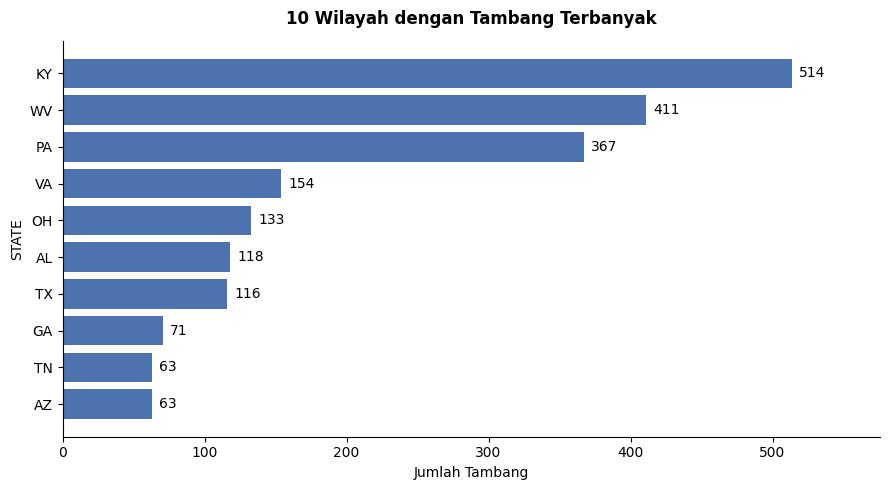

In [ ]:
top_state = df_core["STATE"].value_counts().head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(top_state.index, top_state.values, color="#4C72B0")

ax.bar_label(bars, padding=5, fmt="{:,.0f}")
ax.set_xlim(0, top_state.max() * 1.12)  # Beri ruang di kanan agar label tidak terpotong

ax.set_title("10 Wilayah dengan Tambang Terbanyak", pad=12, fontweight="bold")
ax.set_xlabel("Jumlah Tambang")
ax.set_ylabel("STATE")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

**Interpretation:**

Grafik menunjukkan **10 negara bagian (`STATE`) dengan jumlah tambang terbanyak** diurutkan dari terbesar (`KY`) ke terkecil di top-10 (`AZ`).

### Poin Utama

* **Sangat terpusat di 3 besar**:
  - **Kentucky (`KY`, 514)**, **West Virginia (`WV`, 411)**, dan **Pennsylvania (`PA`, 367)** memimpin jauh di atas wilayah lain (total 1.292 tambang, atau sekitar 43% dari seluruh 2.996 data).

* **Penurunan tajam setelah 3 besar**:
  - Dari `PA` (367) turun drastis ke **Virginia (`VA`, 154)**—kurang dari setengahnya—lalu melandai bertahap ke **Ohio (`OH`, 133)**, **Alabama (`AL`, 118)**, dan **Texas (`TX`, 116)**.

* **Kelompok ekor top-10**:
  - **Georgia (`GA`, 71)**, **Tennessee (`TN`, 63)**, dan **Arizona (`AZ`, 63)** berada di urutan terbawah top-10 dengan jumlah yang relatif berdekatan (bahkan `TN` dan `AZ` seri).

### b) Composition of mine types (bars)

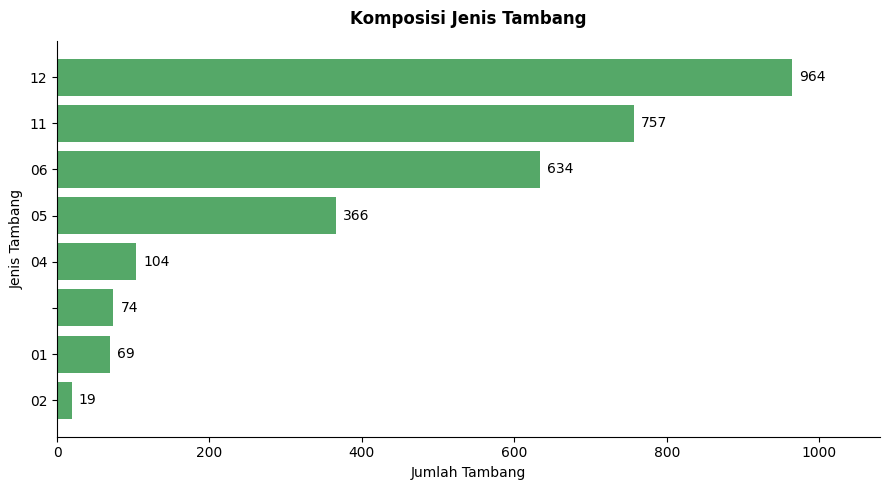

In [ ]:
jenis = df_core["MINE_TYPE"].value_counts().head(8).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(jenis.index.astype(str), jenis.values, color="#55A868")

ax.bar_label(bars, padding=5, fmt="{:,.0f}")
ax.set_xlim(0, jenis.max() * 1.12)  # Ruang ekstra di kanan agar label tidak terpotong

ax.set_title("Komposisi Jenis Tambang", pad=12, fontweight="bold")
ax.set_xlabel("Jumlah Tambang")
ax.set_ylabel("Jenis Tambang")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

**Interpretation:**


Grafik menampilkan **komposisi 8 jenis tambang (`MINE_TYPE`) teratas** dari terbesar (`12`) ke terkecil (`02`).

Poin Utama

* **Didominasi 3 jenis teratas**:
  - Kode **`12` (964)**, **`11` (757)**, dan **`06` (634)** mencakup mayoritas besar data (total 2.355 entitas), diikuti **`05` (366)** di posisi keempat.


* **Penurunan tajam setelah 4 besar**:
  - Dari `05` (366) turun drastis ke **`04` (104)**, lalu berlanjut ke kategori tanpa label teks yang terlihat (**74**), **`01` (69)**, dan **`02` (19)**.


* **Label kosong pada bar ke-6 (74)**:
  - Bar bernilai `74` tidak menampilkan kode label pada sumbu Y—kemungkinan berupa string kosong/spasi (`""`) atau nilai yang terpotong saat dikonversi ke label.

### c) Distribution of industrial sectors (NAICSDESCR pie chart)

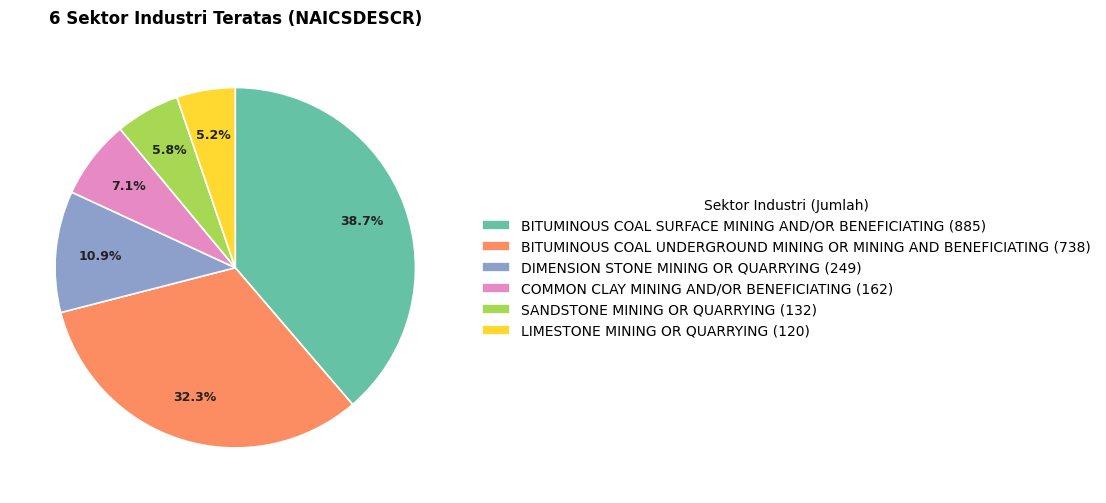

In [ ]:
sektor = df_core["NAICSDESCR"].value_counts().head(6)
colors = sns.color_palette("Set2", len(sektor))

fig, ax = plt.subplots(figsize=(10, 7))
wedges, texts, autotexts = ax.pie(
    sektor.values,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    colors=colors,
    pctdistance=0.75,
    wedgeprops={"edgecolor": "white", "linewidth": 1.2},
)

plt.setp(autotexts, size=9, weight="bold", color="#222222")

legend_labels = [f"{nama} ({jml:,})" for nama, jml in sektor.items()]
ax.legend(
    wedges,
    legend_labels,
    title="Sektor Industri (Jumlah)",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
)

ax.set_title("6 Sektor Industri Teratas (NAICSDESCR)", pad=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretation:**

Pie chart ini menunjukkan **perbandingan proporsi 6 sektor industri teratas (`NAICSDESCR`)** dari total 2.286 entitas pada 6 kategori teratas tersebut.

### Poin Sederhana

* **Batu bara bituminous mendominasi (~71%)**:
  - Tambang batu bara terbuka (`38,7%` | 885) dan bawah tanah (`32,3%` | 738) menyumbang porsi terbesar di kelompok ini.

* **Batu & tanah liat mengisi sisanya (~29%)**:
  - Terdiri dari batu dimensi (`10,9%` | 249), tanah liat umum (`7,1%` | 162), batu pasir (`5,8%` | 132), dan batu kapur (`5,2%` | 120) dengan selisih antar-kategori yang jauh lebih kecil.

* **Persentase relatif**:
  - Angka persen di grafik dihitung dari **jumlah 6 sektor teratas ini saja**, bukan dari seluruh 2.996 baris dataset.

## Companies with the Most Mines

In [ ]:
def top_perusahaan_tambang(
    df: pd.DataFrame,
    kolom: str = "COMPNAME",
    top_n: int = 10,
    drop_kosong: bool = True,
) -> pd.Series:
    """Ambil dan cetak peringkat perusahaan dengan jumlah tambang terbanyak.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame sumber data tambang.
    kolom : str, default "COMPNAME"
        Nama kolom berisi nama perusahaan.
    top_n : int, default 10
        Jumlah perusahaan teratas yang ditampilkan.
    drop_kosong : bool, default True
        Jika True, abaikan nilai kosong/spasi setelah di-strip.

    Returns
    -------
    pd.Series
        Series jumlah tambang per perusahaan (top_n).
    """
    seri = df_core[kolom].astype("string").str.strip()
    if drop_kosong:
        seri = seri.replace("", pd.NA).dropna()

    top_comp = seri.value_counts().head(top_n)

    print(f"{top_n} perusahaan dengan tambang terbanyak:")
    if top_comp.empty:
        print("(Tidak ada data perusahaan yang valid)")
    else:
        for peringkat, (nama, jumlah) in enumerate(top_comp.items(), start=1):
            print(f"{peringkat:>2}. {nama:<55} {jumlah:>4,}")

    return top_comp


top_comp = top_perusahaan_tambang(df_core, top_n=10, drop_kosong=True)

10 perusahaan dengan tambang terbanyak:
 1. COLD SPRING GRANITE COMPANY                               15
 2. OXFORD MINING                                             15
 3. CAM MINING LLC                                            13
 4. PARAMONT COAL COMPANY VIRGINIA                            13
 5. ROSEBUD MINING COMPANY                                    12
 6. CONSOLIDATION COAL COMPANY                                11
 7. BLACK BEAUTY COAL COMPANY                                 11
 8. AMFIRE MINING COMPANY LLC                                 10
 9. ACME BRICK COMPANY                                         9
10. PREMIER ELKHORN COAL COMPANY                               9


**Interpretation:**

Output tersebut menampilkan **10 perusahaan dengan jumlah entitas tambang terbanyak** setelah nilai kosong dibersihkan (total 120 tambang dari 10 perusahaan teratas ini).

### Poin Utama

* **Sebaran cukup merata di papan atas**:
  - Tidak ada satu perusahaan yang mendominasi sendirian secara ekstrem; peringkat 1 sampai 10 berada di rentang sempit antara **9 hingga 15 tambang**.

* **Peringkat teratas berbagi posisi**:
  - **Cold Spring Granite Company** dan **Oxford Mining** sama-sama memimpin dengan **15 tambang**, diikuti ketat oleh **CAM Mining LLC** dan **Paramont Coal Company Virginia** (**13 tambang**), lalu **Rosebud Mining Company** (**12 tambang**).

* **Dominasi nama terkait batu bara & material bangunan**:
  - Banyak entitas di daftar ini memuat kata *Coal* atau *Mining* (seperti *Consolidation Coal*, *Black Beauty Coal*, *Premier Elkhorn Coal*, *Oxford Mining*, *Rosebud Mining*, *CAM Mining*, *Amfire Mining*), serta pemain material batu/bata seperti *Cold Spring Granite* dan *Acme Brick*.

* **Catatan penulisan nama perusahaan**:
  - Perlu diingat bahwa perhitungan ini masih berbasis string persis (`COMPNAME`)—misalnya `OXFORD MINING` di sini tercatat 15, jadi jika ada variasi penulisan lain di luar daftar (seperti tambahan `LLC`/`INC`), jumlah sebenarnya per grup usaha bisa sedikit berbeda.

## Automated Report (Narrative Summary)

Saya akan merangkum temuan kunci sebagai "laporan" yang bisa dicetak ulang kapan pun data diperbarui.

In [ ]:
import pandas as pd


def _modus_bersih(seri: pd.Series, abaikan_kosong: bool = True) -> tuple[str, int]:
    """Kembalikan nilai dominan beserta jumlahnya secara aman."""
    s = seri.astype("string").str.strip()
    if abaikan_kosong:
        s = s.replace("", pd.NA).dropna()

    vc = s.value_counts()
    if vc.empty:
        return "-", 0
    return str(vc.index[0]), int(vc.iloc[0])


def laporan_tambang(data: pd.DataFrame) -> dict[str, object]:
    """Cetak laporan ringkas direktori tambang dan kembalikan ringkasannya."""
    total = len(data)
    n_wilayah = data["STATE"].nunique(dropna=True)

    wilayah_top, wilayah_jml = _modus_bersih(data["STATE"], abaikan_kosong=True)
    jenis_top, jenis_jml = _modus_bersih(data["MINE_TYPE"], abaikan_kosong=True)
    perusahaan_top, perusahaan_jml = _modus_bersih(data["COMPNAME"], abaikan_kosong=True)
    sektor_top, sektor_jml = _modus_bersih(data["NAICSDESCR"], abaikan_kosong=True)

    garis = "=" * 55
    print(f"{garis}\nLAPORAN RINGKAS DIREKTORI TAMBANG\n{garis}")
    print(f"Total tambang         : {total:,}")
    print(f"Jumlah wilayah (STATE): {n_wilayah:,}")
    print(f"Wilayah terbanyak     : {wilayah_top} ({wilayah_jml:,})")
    print(f"Jenis tambang dominan : {jenis_top} ({jenis_jml:,})")
    print(f"Perusahaan terbesar   : {perusahaan_top} ({perusahaan_jml:,})")
    print(f"Sektor teratas        : {sektor_top} ({sektor_jml:,})")

    return {
        "total_tambang": total,
        "jumlah_wilayah": n_wilayah,
        "wilayah_terbanyak": wilayah_top,
        "jenis_tambang_dominan": jenis_top,
        "perusahaan_terbesar": perusahaan_top,
        "sektor_teratas": sektor_top,
    }


ringkasan = laporan_tambang(df_core)

LAPORAN RINGKAS DIREKTORI TAMBANG
Total tambang         : 2,996
Jumlah wilayah (STATE): 48
Wilayah terbanyak     : KY (514)
Jenis tambang dominan : 12 (964)
Perusahaan terbesar   : COLD SPRING GRANITE COMPANY (15)
Sektor teratas        : BITUMINOUS COAL SURFACE MINING AND/OR BENEFICIATING (885)


**Interpretation:**

Laporan tersebut merangkum gambaran besar direktori tambang berisi **2.996 entitas** yang tersebar luas secara geografis namun terkonsentrasi pada jenis operasional dan komoditas tertentu.

### Poin Utama

* **Cakupan Luas dengan Titik Pusat Jelas**:
  - Data mencakup **48 wilayah (`STATE`)**, tetapi **Kentucky (`KY`)** menjadi yang terbanyak dengan **514 tambang** (~17,2% dari total data).

* **Dominasi Tipe & Sektor Tertentu**:
  - Jenis tambang berkode **`12`** memimpin dengan **964 entitas** (32,2%), sejalan dengan sektor teratas **`BITUMINOUS COAL SURFACE MINING AND/OR BENEFICIATING`** sebanyak **885 entitas** (29,5%)—menunjukkan porsi besar penambangan batu bara terbuka (beserta opsional pengolahan awalnya).

* **Pemimpin Perusahaan Tidak Mendominasi Tunggal**:
  - Setelah nilai kosong dibersihkan, **Cold Spring Granite Company** tercatat sebagai entitas dengan jumlah terbanyak (**15 tambang**, sekitar 0,5% dari total)—mengindikasikan bahwa kepemilikan/pencatatan tambang cukup terdistribusi di banyak operator.

### Catatan Singkat untuk Analisis Lanjutan

* Angka dominasi di atas dihitung dari **jumlah baris (`count`) per kategori**, sehingga masih perlu dicek apakah ada variasi penulisan nama perusahaan (`COMPNAME`) atau pemetaan kode `MINE_TYPE` ke keterangan resminya sebelum ditarik kesimpulan bisnis yang lebih dalam.

## Conclusions & Insights

Berdasarkan analisis eksplorasi data (*Exploratory Data Analysis*) terhadap **2.996 direktori tambang**, berikut adalah kesimpulan utama dan *insight* bisnis yang berhasil dihimpun:

### 1. Dominasi Sektor Energi Fosil (Batu Bara)
* **Temuan:**
  -  Industri ini sangat didominasi oleh komoditas batu bara bituminous, baik melalui metode tambang terbuka/permukaan (*Surface Mining*) sebesar **38,7%** maupun tambang bawah tanah (*Underground Mining*) sebesar **32,3%** pada 6 sektor teratas.
* **Insight:**
  - Meskipun kampanye transisi energi hijau terus digaungkan secara global, data operasional ini menunjukkan bahwa infrastruktur dan ketergantungan terhadap energi fosil (khususnya batu bara) di wilayah Amerika Serikat masih sangat masif secara struktural.

### 2. Konsentrasi Geografis di Wilayah Appalachian
* **Temuan:**
  - Tiga negara bagian utama—**Kentucky (KY - 514 tambang)**, **West Virginia (WV - 411 tambang)**, dan **Pennsylvania (PA - 367 tambang)**—menyumbang hampir **43%** dari seluruh titik tambang aktif.
* **Insight:**
  - Daerah-daerah ini merupakan bagian dari sabuk batu bara Appalachian yang legendaris. Konsentrasi yang sangat tinggi ini menyiratkan bahwa perekonomian lokal di wilayah-wilayah tersebut memiliki ketergantungan yang sangat sensitif terhadap regulasi industri pertambangan dan fluktuasi harga komoditas energi.

### 3. Struktur Pasar Fragmented (Terfragmentasi)
* **Temuan:**
  - Pemimpin pasar seperti *Cold Spring Granite Company* dan *Oxford Mining* masing-masing hanya mengoperasikan **15 tambang** (sekitar 0,5% dari total portofolio).
* **Insight:**
  - Industri pertambangan mineral ini tidak dikuasai oleh satu atau dua konglomerasi raksasa yang memonopoli jumlah situs, melainkan dijalankan oleh ribuan operator skala menengah dan kecil (*highly fragmented market*). Hal ini membuka peluang bagi adanya strategi konsolidasi industri (merger & akuisisi) di masa mendatang.

### 4. Kebersihan Data & Rekomendasi Teknis
* **Temuan:**
  - Ditemukan adanya *whitespace* atau string kosong pada kolom `COMPNAME` sebanyak **74 baris** yang tidak terdeteksi langsung sebagai *missing value* (`NaN`) oleh pustaka standar.
* **Insight:**
  - Sebelum melakukan pemodelan prediktif atau integrasi data lebih lanjut, tahap pembersihan (*data cleaning*) secara spesifik seperti `.str.strip()` dan penanganan nilai kosong tersembunyi sangat krusial agar analisis tidak bias.
